In [1]:
# =========================
# Importación de librerías
# =========================

# =========================
# Librería principal NumPyro
# =========================
import numpyro

numpyro.set_host_device_count(3)

import jax

# jax.numpy:
# Versión de NumPy optimizada para JAX.
# Permite operaciones vectorizadas y diferenciación automática.
import jax.numpy as jnp

# Generador de números aleatorios de JAX.
# JAX usa llaves funcionales en lugar de estados globales.
import jax.random as random

# Librería base para gráficas.
import matplotlib.pyplot as plt

# NumPy tradicional.
# Útil para generación de datos y manejo general.
import numpy as np

# Distribuciones probabilísticas de NumPyro
# (Normal, Bernoulli, Beta, etc.).
import numpyro.distributions as dist

# Manipulación de tablas tipo DataFrame.
import pandas as pd

# Librería de visualización estadística
# construida sobre matplotlib.
import seaborn as sns

# Herramientas de inferencia bayesiana:
# - MCMC: ejecuta cadenas de Monte Carlo.
# - NUTS: algoritmo Hamiltoniano adaptativo.
from numpyro.infer import MCMC, NUTS

plt.style.use("ggplot")

print("Backend predeterminado:", jax.default_backend())
print("CPU:", jax.local_device_count("cpu"))
print("GPU:", jax.local_device_count("gpu"))

Backend predeterminado: gpu
CPU: 3
GPU: 1


# Modelo Poisson Gamma

In [2]:
def modelo_poisson_gamma(data, alpha=10.0, beta=1.0):

    lamb = numpyro.sample("lambda", dist.Gamma(alpha, beta))

    num_muestras = len(data)

    with numpyro.plate("data", num_muestras):

        numpyro.sample("x", dist.Poisson(lamb), obs=data)

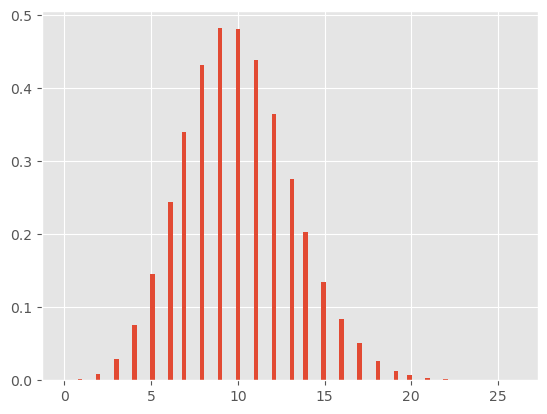

In [3]:
# semilla
key = random.PRNGKey(124657)

# datos generados
lambda_real = 10.0

n_data = 100_000

x = dist.Poisson(lambda_real).sample(key=key, sample_shape=(n_data,))

plt.hist(x, bins=100, density=True)
plt.show()

In [4]:
# Parámetros para el muestreo
n_samples = 1000
burn_in = 2000
n_chains = 3
method = "vectorized"  # si se usa gp method = "parallel"

# MOnte Calor Hamiltoniano con NUTS
nuts_kernel = NUTS(modelo_poisson_gamma)

# Objeto mcmc para muestrear
mcmc = MCMC(
    nuts_kernel,
    num_samples=n_samples,
    num_warmup=burn_in,
    num_chains=n_chains,
    chain_method=method,
)

# sub semilla
key, subkey = random.split(key)
mcmc.run(subkey, data=jnp.array(x), alpha=10.0, beta=1.0)

  0%|                                                                                        | 0/3000 [00:00<?, ?it/s]

warmup:   5%|███▍                                                                 | 150/3000 [00:01<00:24, 116.76it/s]

warmup:  11%|███████▍                                                             | 321/3000 [00:01<00:09, 276.14it/s]

warmup:  17%|███████████▋                                                         | 510/3000 [00:01<00:05, 477.88it/s]

warmup:  24%|████████████████▋                                                    | 727/3000 [00:01<00:03, 733.87it/s]

...

sample:  74%|█████████████████████████████████████████████████▉                 | 2234/3000 [00:02<00:00, 1906.51it/s]

sample:  81%|██████████████████████████████████████████████████████▎            | 2434/3000 [00:02<00:00, 1932.26it/s]

sample:  88%|██████████████████████████████████████████████████████████▋        | 2626/3000 [00:02<00:00, 1928.25it/s]

sample:  94%|██████████████████████████████████████████████████████████████▉    | 2816/3000 [00:02<00:00, 1916.39it/s]

sample: 100%|███████████████████████████████████████████████████████████████████| 3000/3000 [00:02<00:00, 1118.34it/s]

In [5]:
# resumen del muestreo
mcmc.print_summary(prob=0.95)


                mean       std    median      2.5%     97.5%     n_eff     r_hat
    lambda     10.00      0.01     10.00      9.98     10.02    989.15      1.00

Number of divergences: 0


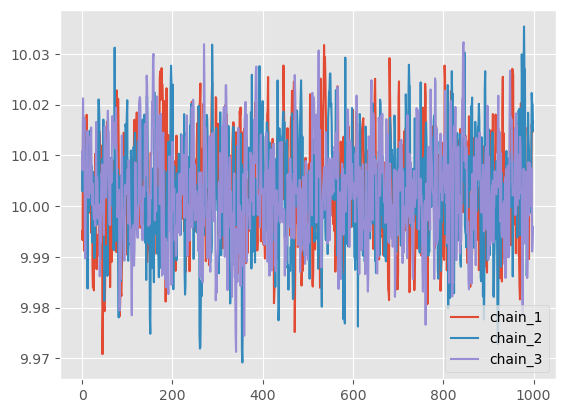

In [15]:
# Trazas
lamb_samples_group_chains = mcmc.get_samples(group_by_chain=True)["lambda"].T
lamb_samples = lamb_samples_group_chains.flatten()

lamb_samples_group_chains = pd.DataFrame(
    lamb_samples_group_chains, columns=["chain_1", "chain_2", "chain_3"]
)

lamb_samples = pd.DataFrame(lamb_samples, columns=["lambda"])

lamb_samples_group_chains.plot()
plt.show()

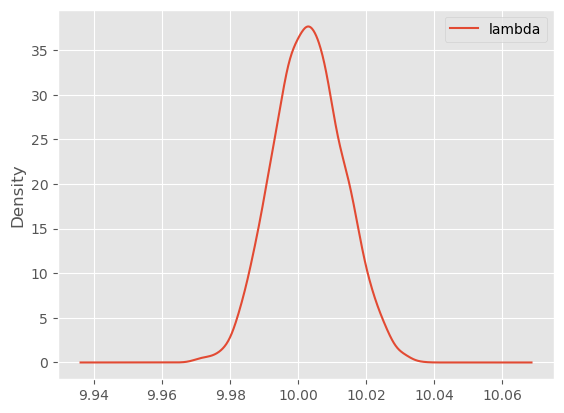

,lambda
count,3000.000000
mean,10.002947
std,0.010242
min,9.969172
2.5%,9.983525
50%,10.002844
97.5%,10.023202
max,10.035404


In [20]:
# Densidad Posterior
lamb_samples.plot.kde()
plt.show()
lamb_samples.describe(percentiles=(0.025, 0.975))

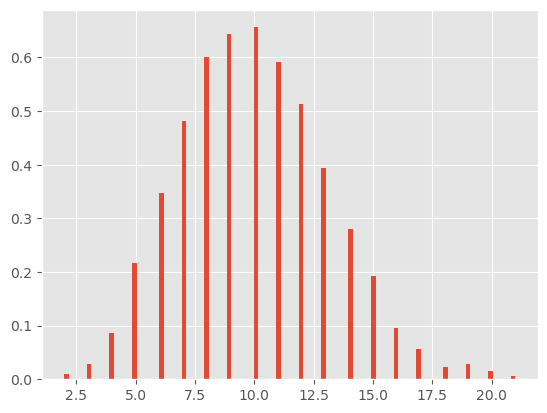

,0
count,3000.000000
mean,9.987667
std,3.116850
min,2.000000
2.5%,5.000000
50%,10.000000
97.5%,16.000000
max,21.000000


In [19]:
key = random.PRNGKey(100)

x_new = dist.Poisson(rate=lamb_samples.values).sample(key)
plt.hist(x_new, density=True, bins=100)
plt.show()
pd.DataFrame(x_new).describe(percentiles=(0.025, 0.975))

# Regresión Lineal

In [2]:
def linear_regression(X, y):

    n, p = X.shape

    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weights = numpyro.sample("weights", dist.Laplace(0.0, 10.0).expand([p]).to_event(1))

    sigma = numpyro.sample("sigma", dist.HalfNormal(1.0))

    mu = bias + jnp.dot(X, weights)

    with numpyro.plate("data", n):

        numpyro.sample("y", dist.Normal(mu, sigma), obs=y)

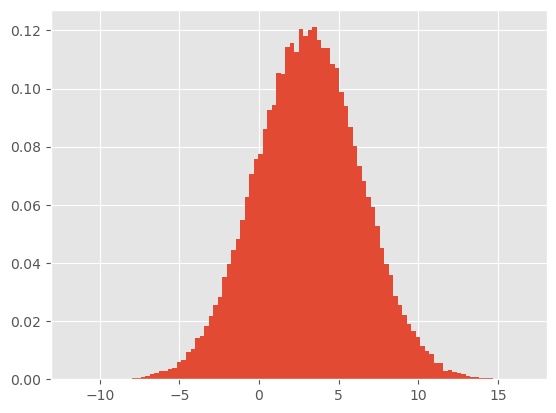

In [9]:
# semilla
key = random.PRNGKey(124657)

# datos generados

real_weights = jnp.array([0.8, 2.5, -1.2, 0.0])
real_bias = 3.1
real_sigma = 1.6

n = 100_000
p = len(real_weights)

X = random.normal(key, (n, p))

y = real_bias + jnp.dot(X, real_weights) + real_sigma * random.normal(key, (n,))


plt.hist(y, bins=100, density=True)
plt.show()

In [10]:
# Parámetros para el muestreo
n_samples = 1000
burn_in = 2000
n_chains = 3
method = "vectorized"  # si se usa gp method = "parallel"

# MOnte Calor Hamiltoniano con NUTS
nuts_kernel = NUTS(linear_regression)

# Objeto mcmc para muestrear
mcmc = MCMC(
    nuts_kernel,
    num_samples=n_samples,
    num_warmup=burn_in,
    num_chains=n_chains,
    chain_method=method,
)

key = random.PRNGKey(124657)
mcmc.run(key, X, y)

  0%|                                                                                        | 0/3000 [00:00<?, ?it/s]

warmup:   5%|███▌                                                                  | 150/3000 [00:17<05:24,  8.78it/s]

warmup:   5%|███▌                                                                  | 150/3000 [00:29<05:24,  8.78it/s]

warmup:   9%|██████▏                                                               | 267/3000 [00:30<05:07,  8.90it/s]

warmup:   9%|██████▎                                                               | 268/3000 [00:30<05:07,  8.90it/s]

...

sample: 100%|████████████████████████████████████████████████████████████████████▉| 2997/3000 [05:37<00:00,  8.98it/s]

sample: 100%|████████████████████████████████████████████████████████████████████▉| 2998/3000 [05:37<00:00,  8.98it/s]

sample: 100%|████████████████████████████████████████████████████████████████████▉| 2999/3000 [05:37<00:00,  9.02it/s]

sample: 100%|█████████████████████████████████████████████████████████████████████| 3000/3000 [05:37<00:00,  9.01it/s]

sample: 100%|█████████████████████████████████████████████████████████████████████| 3000/3000 [05:37<00:00,  8.89it/s]

In [11]:
mcmc.print_summary(prob=0.95)


                mean       std    median      2.5%     97.5%     n_eff     r_hat
      bias      1.13      1.56      0.24     -0.18      3.33      1.50    406.55
     sigma      3.90      1.61      4.84      1.64      5.25      1.50     92.43
weights[0]      0.41      1.04      0.84     -1.03      1.41      1.50   2687.09
weights[1]      0.56      1.60     -0.28     -0.85      2.80      1.50   2674.13
weights[2]     -0.49      0.51     -0.35     -1.17      0.06      1.50    854.74
weights[3]      0.15      0.94     -0.13     -0.84      1.43      1.50    592.27

Number of divergences: 0


In [12]:
samples = mcmc.get_samples(group_by_chain=True)

In [14]:
plt.plot(samples["bias"][:, :, 0].T)

IndexError: Too many indices: array is 2-dimensional, but 3 were indexed

In [23]:
jnp.array([[1, 2, 3], [4, 5, 6]]).shape

(2, 3)